# TIR ujCLST Whole-Hole Clustering

This notebook investigates exploratory clustering of the 20-hole team cohort using processed TIR mineral interpretations from the `Grp1 ujCLST` log.

## Objective

The aim is to determine whether drill holes show meaningful similarity patterns based on their whole-hole primary TIR mineral-group composition.

Each drill hole is represented by the proportions of valid `Grp1 ujCLST` categories observed across the hole. These proportions are used as features for exploratory K-Means clustering.

## Dataset

- Selection: `team_raw_tsg_20`
- Number of holes: 20
- Source: Processed TSG data
- Spectral region: TIR
- Interpretation: jCLST
- Feature log: `Grp1 ujCLST`
- Unit of clustering: Drill hole

## Baseline approach

The processed TSG baseline workflow is adapted for the TIR `Grp1 ujCLST` representation:

1. Load prepared whole-hole mineral-group proportions.
2. Exclude constant features.
3. Standardize varying features using `StandardScaler`.
4. Apply K-Means clustering.
5. Compare candidate values of k.
6. Assess cluster stability across different K-Means initializations.
7. Inspect cluster mineral-group profiles.
8. Use PCA only for 2D visualization of the standardized feature space.
9. Perform a scaled-vs-unscaled sensitivity check.

The resulting clusters represent exploratory similarity between whole-hole mineral profiles. They should not be interpreted as geological deposit classes or ground-truth labels.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

from hylogger.baseline import (
    fit_baseline,
    load_baseline_inputs,
    save_baseline_run,
)
from hylogger.config import AppConfig

In [2]:
# Change these settings here before running the remaining cells.
SELECTION = "team_raw_tsg_20"       # Named cohort from configs/selections/.
FEATURE_LOG = "grp1_uj_clst"   # One shared user-level TIR group log, not all numeric columns.
N_CLUSTERS = 2               # Baseline candidate after comparing k=2–5 across the 20-hole TIR cohort.
RANDOM_STATE = 42            # Reproducible K-Means initialisation.
PCA_VARIANCE = None          # None: no PCA; set 0.95 to apply PCA before K-Means.

config = AppConfig.load()    # Finds the installed project, even when launched elsewhere.

## 1. Load and quality-check the prepared TIR features

The processed TSG data for the 20-hole cohort were prepared using the project's existing `hylogger prepare` workflow.

For this baseline, each hole is represented using the proportions of valid primary mineral-group labels from `Grp1 ujCLST`.

Before clustering, the prepared inputs are checked to confirm that:

- all 20 selected holes are represented;
- the requested `Grp1 ujCLST` log is available;
- each hole contains valid observations;
- missing or invalid readings are not treated as valid mineral groups; and
- unobserved mineral-group categories can be represented as zero only after the parent log has been confirmed as valid.

The clustering unit is the **whole drill hole**, not an individual depth or spectrum.

In [3]:
inputs = load_baseline_inputs(config, SELECTION, feature_log=FEATURE_LOG)
print(f"Loaded {len(inputs.proportions)} holes from processed logs only.")
display(inputs.quality.round(2))
low_coverage = inputs.quality.index[inputs.quality["valid_pct"] < 50].tolist()
if low_coverage:
    print(f"Review these holes: fewer than half their rows have valid labels: {low_coverage}")
    print("This is a warning for review, not an automatic exclusion threshold.")

Loaded 20 holes from processed logs only.


,total_rows,valid_rows,missing_rows,invalid_rows,valid_pct,missing_pct,invalid_pct
hole_id,,,,,,,
13TRDD012,119662,90543,29118,1,75.67,24.33,0.00
13TRDD013,47704,37276,10428,0,78.14,21.86,0.00
15RCDVZ001,61881,46559,15322,0,75.24,24.76,0.00
16CADD002,134804,105001,29803,0,77.89,22.11,0.00
16MYD0047,84420,63527,20893,0,75.25,24.75,0.00
16MYD0052,59354,45598,13755,1,76.82,23.17,0.00
22USDH0207,87071,86429,206,436,99.26,0.24,0.50
EPT2276,59840,43481,16357,2,72.66,27.33,0.00
FDH002,42940,32561,10379,0,75.83,24.17,0.00


## 2. Explore whole-hole TIR mineral-group profiles

Before clustering, the `Grp1 ujCLST` proportions are inspected to understand how mineral-group composition varies across the 20 drill holes.

Each row represents one drill hole, and the features represent the proportion of valid primary `Grp1 ujCLST` observations assigned to each mineral group.

The proportions for each hole sum to 1 (100%). These values represent the relative frequency of processed TIR mineral-group labels within each hole; they should not be interpreted directly as physical rock-volume percentages.

The stacked bar chart provides an initial visual comparison of the whole-hole profiles before any clustering is applied.

,amphibole,carbonate,chlorite,dark_mica,epidote,garnet,k_feldspar,kaolin,olivine,other_aloh,...,oxide,phosphate,plagioclase,pyroxene,serpentine,silica,smectite,sulphate,tourmaline,white_mica
hole_id,,,,,,,,,,,,,,,,,,,,,
13TRDD012,0.22,2.39,3.29,0.00,0.18,0.00,0.05,0.00,0.00,0.01,...,0.00,0.00,18.55,0.00,0.00,73.19,0.15,0.04,0.00,1.77
13TRDD013,1.50,0.98,2.88,0.00,3.12,0.00,0.17,0.00,0.00,0.00,...,0.00,0.00,17.00,0.00,0.01,73.80,0.01,0.00,0.00,0.54
15RCDVZ001,23.48,1.75,4.40,0.03,0.27,0.01,0.51,0.00,0.00,1.02,...,0.00,0.00,21.43,0.00,0.86,41.28,0.01,0.12,0.00,0.13
16CADD002,0.00,3.16,0.44,0.00,0.00,0.00,0.15,0.00,0.00,0.01,...,0.00,0.00,3.94,0.00,0.00,91.75,0.00,0.02,0.00,0.48
16MYD0047,6.52,3.69,1.47,3.07,0.03,0.00,1.66,0.00,0.00,0.07,...,0.00,0.00,31.15,6.30,0.00,44.84,0.29,0.00,0.00,0.90
16MYD0052,4.58,6.09,1.68,1.91,0.01,0.00,0.61,0.00,0.00,0.03,...,0.00,0.00,25.99,6.71,0.00,51.98,0.19,0.00,0.00,0.22
22USDH0207,2.49,0.97,3.96,1.50,1.36,1.74,1.93,1.19,0.00,3.15,...,0.01,0.00,34.50,0.36,0.37,44.39,1.10,0.02,0.06,0.85
EPT2276,0.71,0.66,4.92,0.00,0.48,0.00,7.77,0.00,0.00,0.00,...,0.00,0.00,48.71,0.00,0.03,33.94,0.19,0.00,0.00,2.59
FDH002,1.77,1.88,0.41,0.00,5.48,0.00,0.32,0.01,0.00,0.01,...,0.00,0.00,47.45,0.01,0.00,42.07,0.02,0.03,0.00,0.56


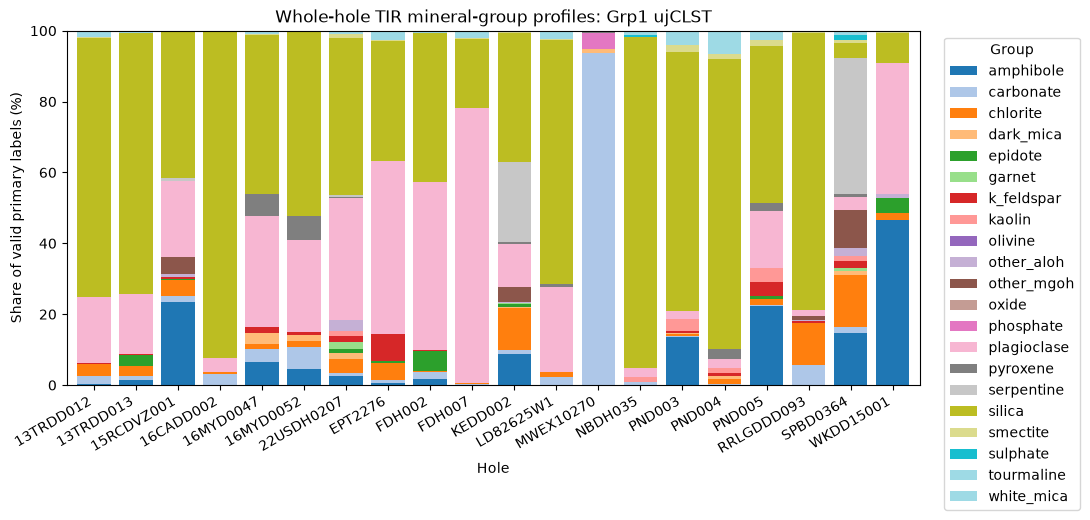

In [4]:
display((inputs.proportions * 100).round(2))
ax = (inputs.proportions * 100).plot.bar(
    stacked=True, figsize=(11, 5), width=0.8, colormap="tab20"
)
ax.set_ylabel("Share of valid primary labels (%)")
ax.set_xlabel("Hole")
ax.set_title(f"Whole-hole TIR mineral-group profiles: Grp1 ujCLST")
ax.legend(title="Group", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 3. Baseline K-Means clustering

K-Means is applied to the whole-hole `Grp1 ujCLST` composition profiles.

The baseline follows the project's existing processed-TSG clustering workflow:

1. Features that are constant across all holes are excluded because they provide no information for separating holes.
2. The remaining mineral-group proportion features are standardized using `StandardScaler`.
3. K-Means is applied to the standardized feature space.
4. PCA is not used as part of the clustering model (`PCA_VARIANCE = None`).

The initial baseline candidate uses `k = 2`. This value is evaluated against alternative values of k in the following section rather than being treated as a known geological number of groups.

Cluster labels such as `0` and `1` are arbitrary identifiers and do not represent geological classes or rankings.

In [5]:
result = fit_baseline(
    inputs,
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    pca_variance=PCA_VARIANCE,
)
display(result.assignments.sort_values(["cluster_id", "hole_id"]))
print(f"Silhouette score: {result.metrics['silhouette_score']:.3f}")
print(f"PCA components: {result.metrics['pca_components']} (None means PCA was not used)")
print(f"Cluster sizes: {result.metrics['cluster_sizes']}")
if result.metrics["has_singleton_cluster"]:
    print("Caution: at least one cluster contains only one hole.")
print(
    "Interpretation: exploratory whole-hole TIR profile similarity; "
    "cluster IDs are not geological class labels."
)


,hole_id,cluster_id
0,13TRDD012,0
1,13TRDD013,0
2,15RCDVZ001,0
3,16CADD002,0
4,16MYD0047,0
5,16MYD0052,0
7,EPT2276,0
8,FDH002,0
9,FDH007,0
10,KEDD002,0


Silhouette score: 0.368
PCA components: None (None means PCA was not used)
Cluster sizes: {'0': 18, '1': 2}
Interpretation: exploratory whole-hole TIR profile similarity; cluster IDs are not geological class labels.


## 4. Compare candidate numbers of clusters

The number of clusters should not be selected arbitrarily. To assess the baseline configuration, K-Means is evaluated for `k = 2` through `k = 5` using the same standardized `Grp1 ujCLST` feature representation.

For each value of k, the following are compared:

- **Silhouette score:** measures how well observations are separated from neighbouring clusters; higher values indicate stronger separation within the same feature representation.
- **Cluster sizes:** identifies highly imbalanced solutions.
- **Singleton clusters:** identifies clusters containing only one drill hole, which may indicate over-fragmentation in this small 20-hole cohort.

This comparison is used to select a practical baseline candidate for further investigation. It does not determine a true geological number of classes.

In [6]:
results_by_k = []

for k in range(2, 6):
    test_result = fit_baseline(
        inputs,
        n_clusters=k,
        random_state=RANDOM_STATE,
        pca_variance=PCA_VARIANCE,
    )

    results_by_k.append({
        "k": k,
        "silhouette_score": test_result.metrics["silhouette_score"],
        "cluster_sizes": test_result.metrics["cluster_sizes"],
        "has_singleton": test_result.metrics["has_singleton_cluster"],
    })

display(pd.DataFrame(results_by_k))

,k,silhouette_score,cluster_sizes,has_singleton
0,2,0.368064,"{'0': 18, '1': 2}",False
1,3,0.356180,"{'0': 17, '1': 2, '2': 1}",True
2,4,0.196646,"{'0': 3, '1': 13, '2': 3, '3': 1}",True
3,5,0.198364,"{'0': 14, '1': 1, '2': 1, '3': 1, '4': 3}",True


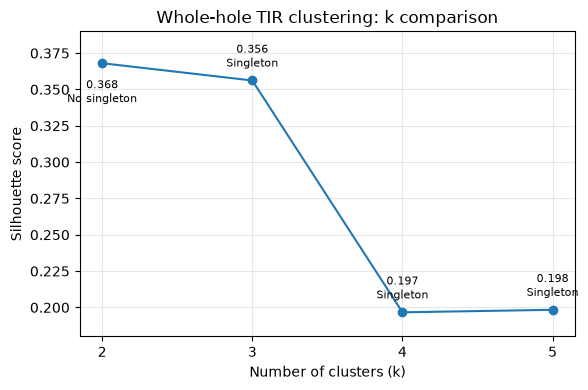

In [9]:
k_df = pd.DataFrame(results_by_k)

plt.figure(figsize=(6, 4))

plt.plot(
    k_df["k"],
    k_df["silhouette_score"],
    marker="o"
)

for _, row in k_df.iterrows():
    status = "No singleton" if not row["has_singleton"] else "Singleton"
    label = f'{row["silhouette_score"]:.3f}\n{status}'

    plt.annotate(
        label,
        (row["k"], row["silhouette_score"]),
        xytext=(0, -28 if row["k"] == 2 else 10),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

plt.xticks(k_df["k"])
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Whole-hole TIR clustering: k comparison")
plt.ylim(0.18, 0.39)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Baseline selection

Among the tested values (`k = 2–5`), `k = 2` produced the highest silhouette score (approximately 0.368) and was the only tested solution without a singleton cluster.

The `k = 3` solution produced a similar silhouette score (approximately 0.356) but introduced a singleton cluster, while `k = 4` and `k = 5` produced substantially lower silhouette scores and additional fragmentation.

Therefore, `k = 2` is retained as the baseline candidate for further analysis. This should be interpreted as the most suitable exploratory configuration among the values tested here, rather than evidence that the drill holes form exactly two geological classes.

## 5. Inspect the k=2 baseline solution

The retained `k = 2` baseline separates the 20-hole cohort into:

- one larger cluster containing 18 holes; and
- one smaller cluster containing `22USDH0207` and `SPBD0364`.

To understand this result, the clusters are compared using both:

1. the original `Grp1 ujCLST` proportions, which show differences in average mineral-group composition; and
2. the standardized feature values actually used by K-Means.

The standardized comparison is important because K-Means is fitted after `StandardScaler`. Therefore, mineral groups with relatively small raw proportions can still contribute strongly to separation when their occurrence varies substantially across the cohort.

These comparisons are descriptive and should not be interpreted as formal feature importance or as evidence that any single mineral group caused the clustering.

In [52]:
k2_result = fit_baseline(
    inputs,
    n_clusters=2,
    random_state=RANDOM_STATE,
    pca_variance=PCA_VARIANCE,
)

display(
    k2_result.assignments
    .sort_values(["cluster_id", "hole_id"])
)

,hole_id,cluster_id
0,13TRDD012,0
1,13TRDD013,0
2,15RCDVZ001,0
3,16CADD002,0
4,16MYD0047,0
5,16MYD0052,0
7,EPT2276,0
8,FDH002,0
9,FDH007,0
10,KEDD002,0


### Interpretation of the baseline clusters

In the original proportion space, the smaller two-hole cluster shows notable compositional differences from the larger cluster, including higher average serpentine and chlorite proportions and lower average silica.

However, the standardized feature comparison shows that separation is influenced by a combination of mineral groups. Several relatively rare groups also show large standardized differences between the two clusters.

Because all varying features are standardized before K-Means, the cluster separation should therefore be interpreted as a multivariate difference in whole-hole mineral-group profiles rather than being attributed to one dominant mineral group.

In [34]:
assignments = k2_result.assignments.set_index("hole_id")

comparison = inputs.proportions.copy()
comparison["cluster_id"] = assignments["cluster_id"]

cluster_profiles = comparison.groupby("cluster_id").mean() * 100

display(cluster_profiles.round(2))

,amphibole,carbonate,chlorite,dark_mica,epidote,garnet,k_feldspar,kaolin,olivine,other_aloh,...,oxide,phosphate,plagioclase,pyroxene,serpentine,silica,smectite,sulphate,tourmaline,white_mica
cluster_id,,,,,,,,,,,,,,,,,,,,,
0,7.24,6.93,2.81,0.41,0.88,0.01,0.96,0.61,0.00,0.13,...,0.00,0.25,21.66,1.09,1.31,53.19,0.37,0.07,0.00,1.51
1,8.53,1.43,9.34,1.28,0.72,1.18,1.99,1.25,0.01,2.78,...,0.01,0.00,19.10,0.66,19.41,24.21,1.02,0.69,0.06,1.03


In [56]:
varying = inputs.proportions.columns[
    inputs.proportions.nunique() > 1
].tolist()

scaler = StandardScaler()

scaled_values = pd.DataFrame(
    scaler.fit_transform(inputs.proportions[varying]),
    index=inputs.proportions.index,
    columns=varying,
)

scaled_values["cluster_id"] = assignments["cluster_id"]

scaled_cluster_profiles = scaled_values.groupby("cluster_id").mean()

difference = (
    scaled_cluster_profiles.loc[1] - scaled_cluster_profiles.loc[0]
).abs().sort_values(ascending=False)

display(difference.to_frame("absolute_standardised_difference").round(2))

,absolute_standardised_difference
tourmaline,3.33
other_aloh,3.11
garnet,2.97
sulphate,2.12
serpentine,1.91
other_mgoh,1.83
oxide,1.61
chlorite,1.55
smectite,1.11
dark_mica,1.05


## 6. Assess clustering stability across K-Means initializations

K-Means can produce different solutions depending on its initial cluster centres. To assess whether the `k = 2` result is dependent on a particular random initialization, the same standardized feature matrix is clustered repeatedly using 10 different random seeds.

Agreement between the resulting cluster assignments is measured using the Adjusted Rand Index (ARI).

An ARI of 1 indicates identical grouping, while lower values indicate increasing disagreement between solutions. Cluster ID numbers themselves are arbitrary and do not affect ARI.

In [53]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

# Use the same varying features and StandardScaler
# as the baseline clustering pipeline.
X_scaled = StandardScaler().fit_transform(
    inputs.proportions[varying]
)

label_sets = {}

for seed in range(10):
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=20,
    )
    label_sets[seed] = model.fit_predict(X_scaled)

ari_scores = []

for seed_a, seed_b in combinations(label_sets.keys(), 2):
    ari_scores.append(
        adjusted_rand_score(
            label_sets[seed_a],
            label_sets[seed_b]
        )
    )

print("Number of K-Means runs:", len(label_sets))
print("Number of pairwise comparisons:", len(ari_scores))
print("Mean ARI:", round(sum(ari_scores) / len(ari_scores), 3))
print("Minimum ARI:", round(min(ari_scores), 3))
print("Maximum ARI:", round(max(ari_scores), 3))

Number of K-Means runs: 10
Number of pairwise comparisons: 45
Mean ARI: 0.781
Minimum ARI: 0.383
Maximum ARI: 1.0


In [37]:
for seed, labels in label_sets.items():
    temp = pd.DataFrame({
        "hole_id": inputs.proportions.index,
        "cluster": labels
    })

    clusters = (
        temp.groupby("cluster")["hole_id"]
        .apply(list)
        .to_dict()
    )

    print(f"\nSeed {seed}")
    for cluster_id, holes in clusters.items():
        print(f"  Cluster {cluster_id} ({len(holes)} holes): {holes}")


Seed 0
  Cluster 0 (18 holes): ['13TRDD012', '13TRDD013', '15RCDVZ001', '16CADD002', '16MYD0047', '16MYD0052', 'EPT2276', 'FDH002', 'FDH007', 'KEDD002', 'LD82625W1', 'MWEX10270', 'NBDH035', 'PND003', 'PND004', 'PND005', 'RRLGDDD093', 'WKDD15001']
  Cluster 1 (2 holes): ['22USDH0207', 'SPBD0364']

Seed 1
  Cluster 0 (2 holes): ['22USDH0207', 'SPBD0364']
  Cluster 1 (18 holes): ['13TRDD012', '13TRDD013', '15RCDVZ001', '16CADD002', '16MYD0047', '16MYD0052', 'EPT2276', 'FDH002', 'FDH007', 'KEDD002', 'LD82625W1', 'MWEX10270', 'NBDH035', 'PND003', 'PND004', 'PND005', 'RRLGDDD093', 'WKDD15001']

Seed 2
  Cluster 0 (18 holes): ['13TRDD012', '13TRDD013', '15RCDVZ001', '16CADD002', '16MYD0047', '16MYD0052', '22USDH0207', 'EPT2276', 'FDH002', 'FDH007', 'LD82625W1', 'MWEX10270', 'NBDH035', 'PND003', 'PND004', 'PND005', 'RRLGDDD093', 'WKDD15001']
  Cluster 1 (2 holes): ['KEDD002', 'SPBD0364']

Seed 3
  Cluster 0 (18 holes): ['13TRDD012', '13TRDD013', '15RCDVZ001', '16CADD002', '16MYD0047', '16MYD0

### Stability result

Across 10 K-Means initializations, the mean pairwise ARI was approximately **0.781**, with values ranging from **0.383 to 1.000**.

This indicates fairly strong average agreement between runs, but the solution is not completely invariant to initialization.

The dominant visible solution separates `22USDH0207` and `SPBD0364` from the remaining holes. Alternative initializations can instead pair `SPBD0364` with `KEDD002`, indicating that `SPBD0364` appears persistently distinctive while membership of the second hole in the small cluster is less stable.

The baseline result should therefore be treated as a reasonably stable exploratory pattern rather than a fixed geological classification.

## 7. PCA visualization of the standardized feature space

Principal Component Analysis (PCA) is used here **only for visualization**. PCA is not part of the baseline K-Means clustering model.

The actual baseline clustering is performed directly on the standardized `Grp1 ujCLST` features. PCA subsequently projects the same standardized feature space into two dimensions so that the relative positions of the 20 drill holes can be visualized.

The first two principal components explain approximately:

- PC1: 26.43% of the standardized variance
- PC2: 16.30%
- Combined: 42.72%

Because the two-dimensional projection represents only 42.72% of the total standardized variance, distances in this plot should not be treated as a complete representation of the feature space used by K-Means.

In [54]:
from sklearn.decomposition import PCA

# Standardize the same features used by the baseline model.
X_scaled = StandardScaler().fit_transform(
    inputs.proportions[varying]
)

# Reduce to two dimensions for visualization only.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    index=inputs.proportions.index,
    columns=["PC1", "PC2"]
)

# Add the cluster assignments from our baseline k=2 result.
pca_df["cluster_id"] = assignments["cluster_id"]

print(
    "Variance explained by PC1:",
    round(pca.explained_variance_ratio_[0] * 100, 2),
    "%"
)
print(
    "Variance explained by PC2:",
    round(pca.explained_variance_ratio_[1] * 100, 2),
    "%"
)
print(
    "Total variance shown in 2D:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

display(pca_df)

Variance explained by PC1: 26.43 %
Variance explained by PC2: 16.3 %
Total variance shown in 2D: 42.72 %


,PC1,PC2,cluster_id
hole_id,,,
13TRDD012,-1.244765,0.053068,0
13TRDD013,-1.392427,0.315818,0
15RCDVZ001,0.579262,0.293021,0
16CADD002,-1.572389,0.253183,0
16MYD0047,-0.852704,0.459802,0
16MYD0052,-1.057339,0.604982,0
22USDH0207,3.586575,-0.505210,1
EPT2276,-0.916009,-0.710768,0
FDH002,-1.454225,0.615338,0


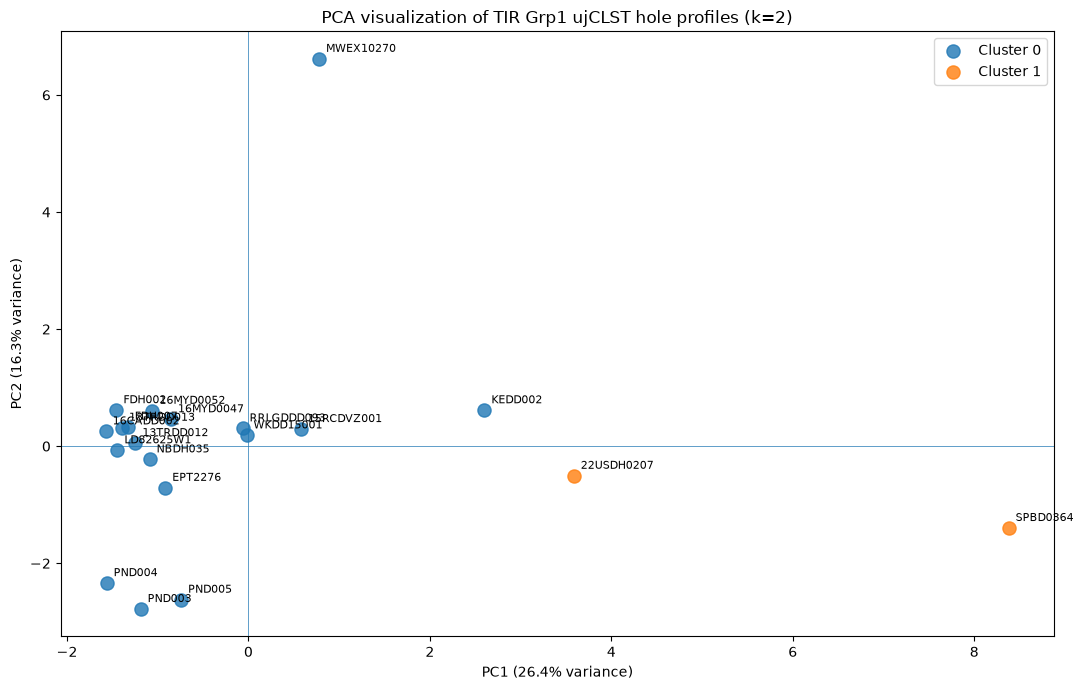

In [55]:
fig, ax = plt.subplots(figsize=(11, 7))

for cluster_id in sorted(pca_df["cluster_id"].unique()):
    cluster_data = pca_df[pca_df["cluster_id"] == cluster_id]

    ax.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        s=90,
        label=f"Cluster {cluster_id}",
        alpha=0.8
    )

# Label every drill hole.
for hole_id, row in pca_df.iterrows():
    ax.annotate(
        hole_id,
        (row["PC1"], row["PC2"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.axhline(0, linewidth=0.5)
ax.axvline(0, linewidth=0.5)

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)"
)

ax.set_title(
    "PCA visualization of TIR Grp1 ujCLST hole profiles (k=2)"
)

ax.legend()
plt.tight_layout()
plt.show()

### PCA visualization interpretation

The PCA projection places `SPBD0364` well away from much of the main group along PC1, while `22USDH0207` and `KEDD002` also occur toward the positive side of PC1.

This is consistent with the stability analysis, where `SPBD0364` remains part of the small cluster while the second member can vary between `22USDH0207` and `KEDD002` under different K-Means initializations.

`MWEX10270` is also visually distinctive along PC2. However, the baseline K-Means model operates in the full standardized feature space rather than this two-dimensional projection.

Therefore, the PCA plot is used as a supporting visualization rather than as evidence for defining the clusters.

## 8. Sensitivity to feature scaling

The baseline follows the project's existing processed-TSG workflow and standardizes the varying mineral-group proportions before K-Means.

A sensitivity analysis is performed to determine whether the resulting cluster assignments remain similar when K-Means is instead applied directly to the unscaled proportions.

This comparison is important because standardization gives each varying mineral-group feature comparable scale. Consequently, relatively rare mineral groups can have greater influence when they vary strongly between holes.

The scaled baseline is retained as the primary workflow; the unscaled analysis is used only to assess sensitivity to this preprocessing choice.

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# --------------------------------------------------
# 1. Scaled baseline
# --------------------------------------------------

X_scaled = StandardScaler().fit_transform(
    inputs.proportions[varying]
)

scaled_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

scaled_labels = scaled_model.fit_predict(X_scaled)

scaled_silhouette = silhouette_score(
    X_scaled,
    scaled_labels
)


# --------------------------------------------------
# 2. Unscaled sensitivity test
# --------------------------------------------------

X_unscaled = inputs.proportions[varying]

unscaled_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

unscaled_labels = unscaled_model.fit_predict(X_unscaled)

unscaled_silhouette = silhouette_score(
    X_unscaled,
    unscaled_labels
)


# --------------------------------------------------
# 3. Compare the two solutions
# --------------------------------------------------

comparison_df = pd.DataFrame({
    "scaled_cluster": scaled_labels,
    "unscaled_cluster": unscaled_labels
}, index=inputs.proportions.index)

agreement_ari = adjusted_rand_score(
    scaled_labels,
    unscaled_labels
)

print("Scaled silhouette:", round(scaled_silhouette, 3))
print("Unscaled silhouette:", round(unscaled_silhouette, 3))
print("ARI between scaled and unscaled solutions:", round(agreement_ari, 3))

display(comparison_df)

Scaled silhouette: 0.368
Unscaled silhouette: 0.358
ARI between scaled and unscaled solutions: -0.046


,scaled_cluster,unscaled_cluster
hole_id,,
13TRDD012,0,1
13TRDD013,0,1
15RCDVZ001,0,0
16CADD002,0,1
16MYD0047,0,0
16MYD0052,0,0
22USDH0207,1,0
EPT2276,0,0
FDH002,0,0


### Scaling sensitivity result

The scaled baseline produced a silhouette score of approximately **0.368**, while the unscaled sensitivity run produced approximately **0.358**.

However, the Adjusted Rand Index between the scaled and unscaled cluster assignments was approximately **-0.046**, indicating very low agreement between the two solutions.

The clustering structure is therefore highly sensitive to whether the mineral-group proportions are standardized.

The two silhouette values should not be interpreted as a direct like-for-like ranking because they are calculated in different feature spaces. The more important finding is that the cluster membership changes substantially with preprocessing.

This sensitivity reinforces the need to interpret the baseline clusters as exploratory similarity patterns rather than definitive geological classes.

## 4. Save the run

Saves assignments, the input proportions, quality counts, feature names, parameters, input checksum and library versions in a new timestamped folder. No downloads or earlier runs are overwritten.

In [57]:
run_dir = save_baseline_run(config, inputs, result, selection=SELECTION)
print(f"Saved run: {run_dir}")

Saved run: /Users/avantikanaudiyal/Downloads/gswa-hylogger-data-crunch-main/gswa-hylogger-data-crunch/experiments/tsg_baseline/20260924T173330_402368Z


## What to ask next

- Which holes received the same cluster ID, and do their group profiles look similar?
- Are different missing/invalid rates affecting how representative each profile is?
- Does a cluster mostly reflect location, acquisition or processing differences?

Cluster numbers are arbitrary labels, not rankings. TSG interpretations are not ground truth. We have not checked every scan generation or processing history for this convenience cohort. Keep this result separate from the raw-spectral workflow in `03_improved_cluster.ipynb`.